# Práctica 3 - Exploración de un dataset con pandas

## Objetivos

En esta práctica trabajarás con un dataset de clientes utilizando Python.

Al finalizar deberás ser capaz de:

- cargar datos desde un archivo CSV
- trabajar con un `DataFrame` de pandas
- identificar muestras y variables
- consultar la estructura de un dataset
- calcular estadísticas descriptivas
- seleccionar y filtrar datos
- analizar variables categóricas
- crear visualizaciones sencillas
- identificar las características \(X\) y la variable objetivo \(y\)
- determinar qué tipo de problema de Machine Learning podría resolverse

> **Importante:** no debes entrenar ningún modelo de Machine Learning en esta práctica.

## Contexto

Una empresa de telecomunicaciones quiere analizar el comportamiento de sus clientes. Dispone de información histórica y conoce qué clientes terminaron abandonando el servicio.

El objetivo futuro será desarrollar un sistema capaz de predecir:

> **¿Qué clientes tienen riesgo de abandonar la compañía?**

Para realizar la práctica utilizaremos el archivo `clientes.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador del cliente |
| `edad` | Edad del cliente |
| `antiguedad` | Meses como cliente |
| `cuota_mensual` | Cuota mensual en euros |
| `consumo_datos` | Consumo mensual de datos en GB |
| `llamadas_soporte` | Número de llamadas a soporte |
| `incidencias` | Número de incidencias registradas |
| `tipo_contrato` | Mensual, anual o bienal |
| `satisfaccion` | Valoración del servicio de 1 a 5 |
| `abandono` | Indica si el cliente abandonó: Sí/No |

Cada fila corresponde a un cliente.

### Instrucciones

Completa las celdas de código marcadas con `# TODO`.

Cuando se solicite una interpretación, escribe tu respuesta en la celda Markdown correspondiente. No basta con ejecutar código: debes **interpretar los resultados**.

## Parte 1 - Preparación del entorno

### Ejercicio 1 - Importación

Importa NumPy, pandas y Matplotlib utilizando los alias convencionales.

In [50]:
#%pip install numpy
#%pip install pandas
#%pip install matplotlib
########################  Comando para instalar librerias dentro del entorno

In [51]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np  #Lo usaremos para trabajr con arrays y operaciones con números
#arrays, operaciones con números
import pandas as pd #Trabajar con DataFrame, que nos permitirá trabajar con tablas
#DaraFrame -> tablas
import matplotlib.pyplot as plt #Es una libreria para hacer gráficos 
#gráficos

### Respuesta

Explica brevemente para qué utilizaremos cada biblioteca:

- **NumPy:**  Lo utilizamos en arrays/listas y cuando vayamos a trabajar con números
- **pandas:**  Lo utilizamos para trabajar con tablas
- **Matplotlib:** Lo utilizamos para visualizar gráfcos

## Parte 2 - Carga e inspección inicial

### Ejercicio 2 - Cargar el dataset

Carga `clientes.csv` en un DataFrame denominado `df` y muestra sus primeras filas.

In [52]:
# TODO: carga el archivo clientes.csv en df
    #pd.read_csv('clientes.csv') Esto devuelve un objeto DataFrame
df = pd.read_csv('clientes.csv')
# TODO: muestra las primeras 
df.head(10) #mostrar 10 filas 


,cliente_id,edad,antiguedad,cuota_mensual,consumo_datos,llamadas_soporte,incidencias,tipo_contrato,satisfaccion,abandono
0,10001,23,61.0,32.16,11.9,1,2,Mensual,1,No
1,10002,62,79.0,45.71,17.4,2,0,Anual,2,No
2,10003,55,49.0,60.48,14.6,0,1,Mensual,5,No
3,10004,43,6.0,116.82,21.8,4,0,Anual,3,No
4,10005,43,70.0,36.13,8.8,2,2,Anual,1,Sí
5,10006,67,3.0,105.63,15.8,2,2,Bienal,2,No
6,10007,22,34.0,36.20,10.2,0,2,Anual,3,Sí
7,10008,58,101.0,53.70,8.1,1,0,Anual,4,No
8,10009,29,56.0,87.67,16.6,2,2,Anual,5,No
9,10010,23,71.0,81.55,13.8,1,1,Mensual,4,No


### Respuesta

**¿Qué representa cada fila del DataFrame?**

Representa un clinte

**¿Qué representa cada columna?**

Las variables de cada cliente

### Ejercicio 3 - Dimensiones

Obtén mediante código las dimensiones del dataset.

In [53]:
# TODO: muestra las dimensiones del DataFrame
df.shape  # Me devuelve cuántas filas y columnas hay en total (su tamaño).

(180, 10)

### Respuesta

- **Número de muestras:180** 
- **Número de variables:10**

### Ejercicio 4 - Columnas

Obtén mediante código los nombres de todas las columnas.

In [54]:
# TODO: muestra los nombres de las columnas
df.columns # Me devuelve todas las columnas que hay en el DataFrame (En el orden en el que han sido creadas)


Index(['cliente_id', 'edad', 'antiguedad', 'cuota_mensual', 'consumo_datos',
       'llamadas_soporte', 'incidencias', 'tipo_contrato', 'satisfaccion',
       'abandono'],
      dtype='str')

### Respuesta

**¿Qué columna parece representar la variable que queremos predecir? ¿Por qué?**

La columna de abandono, ya que nuestro objetivo es saber si un cliente se quedará o se irá.

### Ejercicio 5 - Tipos de datos

Obtén los tipos de datos de todas las columnas.

In [55]:
# TODO: consulta los tipos de datos
df.dtypes

cliente_id            int64
edad                  int64
antiguedad          float64
cuota_mensual       float64
consumo_datos       float64
llamadas_soporte      int64
incidencias           int64
tipo_contrato           str
satisfaccion          int64
abandono                str
dtype: object

### Respuesta

**Variables numéricas:**

8

**Variables categóricas:**

2

**¿`cliente_id` debería considerarse una característica numérica simplemente porque contiene números? Razona la respuesta.**

No, porque es una propiedad que identifica al cliente. NO voy a poder hacer operaciones númericas con él.

## Parte 3 - Estructura y calidad inicial

### Ejercicio 6 - Información general

Utiliza `info()` para analizar la estructura del dataset.

In [56]:
# TODO: muestra la información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cliente_id        180 non-null    int64  
 1   edad              180 non-null    int64  
 2   antiguedad        178 non-null    float64
 3   cuota_mensual     180 non-null    float64
 4   consumo_datos     179 non-null    float64
 5   llamadas_soporte  180 non-null    int64  
 6   incidencias       180 non-null    int64  
 7   tipo_contrato     180 non-null    str    
 8   satisfaccion      180 non-null    int64  
 9   abandono          180 non-null    str    
dtypes: float64(3), int64(5), str(2)
memory usage: 14.2 KB


### Respuesta

- ¿Cuántas entradas contiene?
180 -> (RangeIndex: **180** entries)
- ¿Qué tipos de datos aparecen?
float64, int64 y str 
- ¿Todas las columnas contienen el mismo número de valores no nulos?
No
- ¿Parece existir algún valor ausente?
Si, ya que en antigüedad faltan 2 valores y en consumo_datos 1
- ¿Cómo puedes deducirlo a partir de `info()`?
Se puede saber gracias a los datos "non-null count", que es el recuento de valores no nulos.


## Parte 4 - Estadística descriptiva

### Ejercicio 7 - Descripción estadística

Obtén las estadísticas descriptivas de las variables numéricas.

In [57]:
# TODO: genera las estadísticas descriptivas
df.describe() #Obtengo información general de todas las muestras

# Count número de datos
# mean me devuelve la media aritmética
# std me da la desviación estandard
# min valor mínimo
# max valor máximo
# 25% 50% 75% -> Cuartiles 
#(el 50% es la mediana)

,cliente_id,edad,antiguedad,cuota_mensual,consumo_datos,llamadas_soporte,incidencias,satisfaccion
count,180.000000,180.000000,178.000000,180.000000,179.000000,180.000000,180.000000,180.000000
mean,10090.500000,47.283333,62.050562,71.185667,16.408380,1.705556,1.111111,3.016667
std,52.105662,15.929059,33.991071,29.279251,9.813719,1.249345,1.082563,1.423957
min,10001.000000,18.000000,1.000000,20.480000,1.200000,0.000000,0.000000,1.000000
25%,10045.750000,34.000000,34.000000,43.172500,9.800000,1.000000,0.000000,2.000000
50%,10090.500000,47.000000,61.000000,72.690000,14.300000,1.000000,1.000000,3.000000
75%,10135.250000,62.000000,91.750000,97.177500,20.400000,2.250000,2.000000,4.000000
max,10180.000000,75.000000,120.000000,119.440000,54.200000,6.000000,5.000000,5.000000


### Interpretación

A partir del resultado, indica:

- edad media; 47.283333
- edad mínima; 18   
- edad máxima; 75
- cuota mensual media; 71.185667
- cuota mensual máxima; 119.440000
- media de llamadas a soporte; 1.705556
- media de incidencias; 1.111111
- satisfacción media. 3.016667



### Ejercicio 8 - Cálculos individuales

Calcula mediante instrucciones independientes los valores solicitados.

In [58]:
# TODO: media de edad
print('Media=', df['edad'].mean())
print(f"Media Formateada= {df['edad'].mean():.2f}")

# TODO: mediana de edad
print('Mediana=', df['edad'].median())

# TODO: cuota mínima
print("Cuota mínima= ", df['cuota_mensual'].min())

# TODO: cuota máxima
print("Cuota máxima= ", df['cuota_mensual'].max())

# TODO: número total de incidencias
print("Número total de incidencias= ", df['incidencias'].sum())

# TODO: satisfacción media
print("Satisfacción media= ", df['satisfaccion'].mean())

Media= 47.28333333333333
Media Formateada= 47.28
Mediana= 47.0
Cuota mínima=  20.48
Cuota máxima=  119.44
Número total de incidencias=  200
Satisfacción media=  3.0166666666666666


### Comprobación

¿Coinciden estos resultados con los obtenidos mediante `describe()` cuando corresponde?

Sí, coinciden.

## Parte 5 - Selección de información

### Ejercicio 9 - Selección de columnas

Crea un DataFrame `df_clientes` que contenga únicamente `edad`, `antiguedad`, `cuota_mensual`, `satisfaccion` y `abandono`. Muestra sus primeras cinco filas.

In [59]:
# TODO: crea df_clientes
filtro = ['edad','antiguedad','cuota_mensual','satisfaccion','abandono']
df_clientes = df[filtro]
# TODO: muestra las primeras cinco filas
df_clientes.head()

,edad,antiguedad,cuota_mensual,satisfaccion,abandono
0,23,61.0,32.16,1,No
1,62,79.0,45.71,2,No
2,55,49.0,60.48,5,No
3,43,6.0,116.82,3,No
4,43,70.0,36.13,1,Sí


### Respuesta

**¿Sigue representando cada fila al mismo cliente que en el DataFrame original? Explica por qué.**

Sí, ya que el filtro solamente corta columnas, no filas

## Parte 6 - Filtrado

### Ejercicio 10 - Clientes por edad

Obtén todos los clientes mayores de 50 años y calcula cuántos cumplen la condición.

In [60]:
# TODO: filtra los clientes mayores de 50 años
print(df['edad']>50) # MAL 
mayores_50= df[df['edad']>50]
print("Mayores de 50= ", mayores_50)

#print("Mayores de 50= ", df[df['edad']>50])

# TODO: calcula cuántos son
print("Mayores de 50 = " , len(mayores_50))

0      False
1       True
2       True
3      False
4      False
       ...  
175    False
176     True
177    False
178     True
179    False
Name: edad, Length: 180, dtype: bool
Mayores de 50=       cliente_id  edad  antiguedad  cuota_mensual  consumo_datos  \
1         10002    62        79.0          45.71           17.4   
2         10003    55        49.0          60.48           14.6   
5         10006    67         3.0         105.63           15.8   
7         10008    58       101.0          53.70            8.1   
11        10012    74        27.0          61.04            5.2   
..          ...   ...         ...            ...            ...   
172       10173    62        96.0          35.35           38.5   
173       10174    59        65.0         104.90           26.7   
174       10175    58        66.0          95.67           22.6   
176       10177    59       119.0          74.58           11.2   
178       10179    70        61.0          94.18           43.3   


### Ejercicio 11 - Clientes con incidencias

Selecciona los clientes que tengan `incidencias > 0` y determina cuántos son.

In [61]:
# TODO: filtra los clientes con incidencias
filtro = df['incidencias']>0
#print(filtro)
df_incidencias = df[filtro]
columnas = ['cliente_id','incidencias','satisfaccion']
print(df_incidencias[columnas])

# TODO: calcula cuántos son
print("Clientes con incidencias",len(df_incidencias))

     cliente_id  incidencias  satisfaccion
0         10001            2             1
2         10003            1             5
4         10005            2             1
5         10006            2             2
6         10007            2             3
..          ...          ...           ...
169       10170            1             1
173       10174            1             2
174       10175            2             4
175       10176            1             3
178       10179            1             3

[120 rows x 3 columns]
Clientes con incidencias 120


### Ejercicio 12 - Condiciones combinadas

Obtén los clientes que cumplan simultáneamente:

$$
edad < 30
$$

y


$$llamadas\_soporte \geq 3$$


Muestra únicamente `cliente_id`, `edad`, `llamadas_soporte` y `abandono`.

In [62]:
# TODO: realiza el filtro y muestra únicamente las columnas solicitadas
filtro=(df['edad']<30) & (df['llamadas_soporte']>=3)
df_filtrado=df[filtro]
columnas=['cliente_id','edad','llamadas_soporte','abandono']
print(df_filtrado[columnas])

     cliente_id  edad  llamadas_soporte abandono
17        10018    25                 3       No
22        10023    28                 3       No
35        10036    21                 3       Sí
55        10056    20                 3       No
101       10102    29                 3       No
117       10118    26                 3       Sí
119       10120    24                 3       No
132       10133    23                 4       No
146       10147    20                 3       No
167       10168    27                 6       Sí
169       10170    19                 3       Sí


### Respuesta

**¿Qué operador has utilizado para combinar ambas condiciones?**

El comparador AND

### Ejercicio 13 - Segundo filtro combinado

Localiza clientes que cumplan:

$$satisfaccion \leq 2$$

y

$$incidencias \geq 2$$

Muestra las filas encontradas.

In [63]:
# TODO: realiza el filtro
filtro=(df['satisfaccion']<=2) & (df['incidencias']>=2)
df_filtrado=df[filtro]
print(df_filtrado)

columnas=['cliente_id','satisfaccion','incidencias']
print(df_filtrado[columnas])
print(len(df_filtrado))

     cliente_id  edad  antiguedad  cuota_mensual  consumo_datos  \
0         10001    23        61.0          32.16           11.9   
4         10005    43        70.0          36.13            8.8   
5         10006    67         3.0         105.63           15.8   
11        10012    74        27.0          61.04            5.2   
19        10020    44        55.0          39.62            3.8   
20        10021    47        18.0          37.98           27.6   
24        10025    63        23.0          40.24            7.8   
25        10026    55        34.0          50.03           16.1   
35        10036    21       115.0          41.06           27.0   
44        10045    21       119.0          40.48           16.0   
46        10047    43        85.0         109.32           27.6   
50        10051    62         6.0          92.27            6.1   
59        10060    57        42.0          51.94            6.4   
61        10062    61        37.0          92.74           12.

### Reflexión

**Observando únicamente estos resultados, ¿podemos afirmar que una satisfacción baja provoca el abandono?**

No, se necesitaría continuar el analísis.

## Parte 7 - Variables categóricas

### Ejercicio 14 - Tipo de contrato

Obtén los diferentes valores de `tipo_contrato` y calcula cuántos clientes pertenecen a cada categoría.

In [64]:
# TODO: muestra las categorías existentes
print("Categorias: ", df['tipo_contrato'].unique())

# TODO: calcula la frecuencia de cada categoría
print("Frequencia: ", df['tipo_contrato'].value_counts())

Categorias:  <StringArray>
['Mensual', 'Anual', 'Bienal']
Length: 3, dtype: str
Frequencia:  tipo_contrato
Mensual    94
Anual      56
Bienal     30
Name: count, dtype: int64


### Respuesta

**¿Cuál es el tipo de contrato más frecuente?**

El contrato mensual.

### Ejercicio 15 - Variable `abandono`

Obtén las categorías existentes, el número de clientes de cada categoría y sus frecuencias relativas.

In [65]:
# TODO: categorías existentes
print("Categorias: ", df['abandono'].unique())

# TODO: frecuencias absolutas
print("Frequencia ", df['abandono'].value_counts(normalize=True))

# TODO: frecuencias relativas
print(df["abandono"].value_counts(normalize=True))

Categorias:  <StringArray>
['No', 'Sí']
Length: 2, dtype: str
Frequencia  abandono
No    0.611111
Sí    0.388889
Name: proportion, dtype: float64
abandono
No    0.611111
Sí    0.388889
Name: proportion, dtype: float64


### Interpretación

Expresa las frecuencias relativas mediante porcentajes y redacta una breve conclusión sobre la distribución de `abandono`.

No abandonan (permanecen): 61,11 % (110 clientes).
Sí abandonan: 38,89 % (70 clientes).
La mayoría de los clientes continúa con la empresa, representando el 61,11 % del total. No obstante, el 38,89 % de los clientes ha abandonado la compañía, una proporción considerable que indica que aproximadamente 4 de cada 10 clientes dejan de ser clientes.

## Parte 8 - Visualización

Todos los gráficos deben contener como mínimo:

- título;
- etiquetas de los ejes cuando correspondan;
- una representación clara.

### Ejercicio 16 - Distribución de edad

Construye un histograma de `edad`.

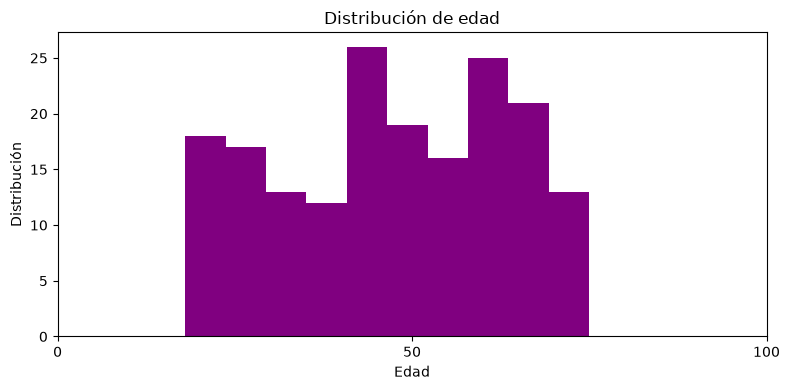

In [66]:
# TODO: crea el histograma de edad
plt.figure(figsize=(8,4)) # 8x4 pulgadas
plt.hist(df['edad'], bins=10, color="purple")
plt.xlabel("Edad")
plt.xticks([0,50,100])
plt.ylabel("Distribución")
plt.title("Distribución de edad")
plt.tight_layout()
plt.show()
#Le tengo que decir = el dato que quiero que pinte

### Interpretación

**¿Qué información proporciona un histograma que no resulta tan fácil obtener observando directamente las filas del DataFrame?**

Sabemos que solo hay mayores de edad y que las edades se concentran desde los 20 hasta los 75 años.

### Ejercicio 17 - Abandono

Representa mediante un gráfico de barras el número de clientes que abandonaron y que no abandonaron.

abandono
No    110
Sí     70
Name: count, dtype: int64


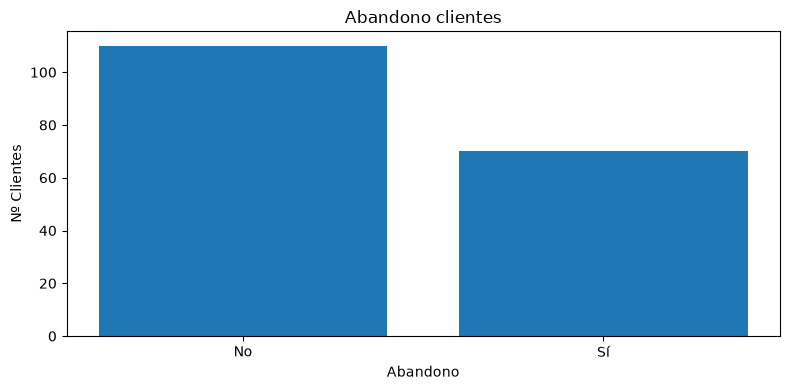

In [67]:
# TODO: crea el gráfico de barras
n_abandonos = df['abandono'].value_counts()
print(n_abandonos)

plt.figure(figsize=(8,4))
plt.bar(n_abandonos.index , n_abandonos.values)
plt.xlabel("Abandono")
plt.ylabel("Nº Clientes")
plt.title("Abandono clientes")
plt.tight_layout()
plt.show()


### Interpretación

Describe brevemente qué muestra el gráfico.

Una comparación simple entre los clientes que abandonan y los que permanecen.

### Ejercicio 18 - Cuota mensual

Crea un histograma para `cuota_mensual`.

cuota_mensual
32.16     1
45.71     1
60.48     1
116.82    1
36.13     1
         ..
117.48    1
74.58     1
41.95     1
94.18     1
73.48     1
Name: count, Length: 180, dtype: int64


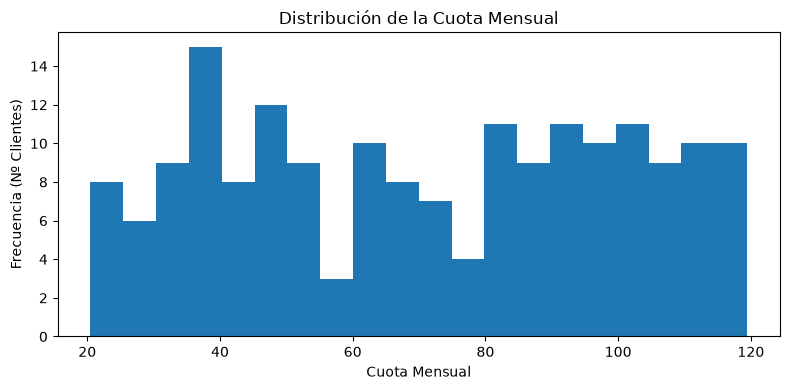

In [68]:
# TODO: crea el histograma de cuota_mensual
n_cuota_mensual = df['cuota_mensual'].value_counts()
print(n_cuota_mensual)

plt.figure(figsize=(8, 4))
plt.hist(df['cuota_mensual'], bins=20)
plt.xlabel("Cuota Mensual")
plt.ylabel("Frecuencia (Nº Clientes)")
plt.title("Distribución de la Cuota Mensual")
plt.tight_layout()
plt.show()

### Interpretación

Analiza visualmente la distribución.

La distribución de la frecuencia suele rondar habitualmente entre los 8 y los 12 clientes, siendo pocas cuotas las excepciones.

### Ejercicio 19 - Edad y cuota

Crea un diagrama de dispersión utilizando:

\[
x = edad
\]

\[
y = cuota\_mensual
\]

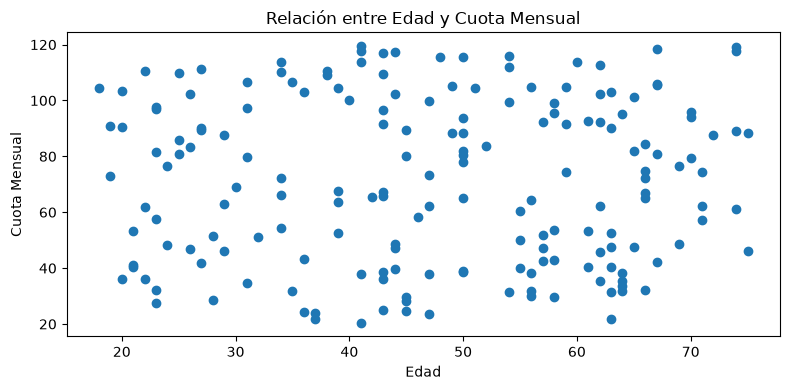

In [69]:
# TODO: crea el diagrama de dispersión

plt.figure(figsize=(8, 4))
plt.scatter(df['edad'], df['cuota_mensual'])
plt.xlabel("Edad")
plt.ylabel("Cuota Mensual")
plt.title("Relación entre Edad y Cuota Mensual")
plt.tight_layout()
plt.show()

### Interpretación

- ¿Qué representa cada punto?  Un cliente.
- ¿Observas a simple vista alguna relación clara entre ambas variables? No, parece estar todo al azar.


## Parte 9 - Identificación de $X$ e $y$

La empresa quiere construir en el futuro un modelo que determine si un cliente abandonará.

### Ejercicio 20 - Variable objetivo

Identifica y crea `y`. Después muestra sus cinco primeros valores.

In [70]:
# TODO: crea y
y=df['abandono']

# TODO: muestra sus cinco primeros valores
y.head()

0    No
1    No
2    No
3    No
4    Sí
Name: abandono, dtype: str

### Respuesta

**¿Por qué esta variable corresponde a \(y\)?**

Porque el objetivo de la empresa es que la gente no abandone.

### Ejercicio 21 - Características

Crea `X` utilizando inicialmente estas características:

- `edad`
- `antiguedad`
- `cuota_mensual`
- `consumo_datos`
- `llamadas_soporte`
- `incidencias`
- `tipo_contrato`
- `satisfaccion`

Después comprueba sus dimensiones.

In [71]:
# TODO: crea X
X = df[[
    'edad',
    'antiguedad',
    'cuota_mensual',
    'consumo_datos',
    'llamadas_soporte',
    'incidencias',
    'tipo_contrato',
    'satisfaccion'
]]

# TODO: muestra las dimensiones de X
print("La dimensión de X es = " , X.shape)

La dimensión de X es =  (180, 8)


### Respuesta

Si el dataset contiene \(n\) clientes, esperamos:

\[
X.shape = (n,\ ?)
\]

**¿Qué número debe aparecer en `?`? ¿Por qué?**

Debe aparecer (8), ya que son las columnas del Data Frame original.

## Parte 10 - Razonamiento de Machine Learning

### Ejercicio 22 - Identificación del problema

Queremos predecir:

`abandono → Sí / No`

Responde razonadamente:

1. ¿Estamos ante aprendizaje supervisado o no supervisado?
2. ¿Por qué?
3. ¿Es clasificación o regresión?
4. ¿Por qué?
5. ¿Es clasificación binaria o multiclase?
6. ¿Cuáles son las clases?

### Respuesta

1. Aprendizaje supervisado.
2. Porque los datos cuentan con una variable objetivo (abandono). El modelo puede aprender a predecir a partir de ejemplos históricos.
3. Clasificación.
4. Porque la variable que queremos predecir es categórica.
5. Clasificación binaria.
6. Ambas clases son "si" y "no".

## Parte 11 - Un cambio en el problema

Supongamos ahora que la empresa plantea:

> Queremos predecir cuál será el **consumo de datos del próximo mes** de cada cliente.

### Ejercicio 23

Responde:

1. ¿Cuál sería ahora la variable objetivo?
2. ¿Seguiríamos teniendo exactamente el mismo \(X\)?
3. ¿Sería clasificación o regresión?
4. ¿Seguiría siendo aprendizaje supervisado?
5. Justifica cada respuesta.

### Respuesta

1. La variable objetivo es el consumo de datos del próximo mes, ya que es el valor que la empresa quiere predecir para cada cliente.
2. No, porque para predecir el consumo de datos futuro necesitamos utilizar información diferente a la empleada anteriormente. En este caso, debemos analizar nuevos datos que puedan ayudar a realizar la predicción.
3. Se trata de un problema de regresión, debido a que el consumo de datos es un valor numérico continuo que puede tomar diferentes cantidades.
4. Sí, es necesario utilizar datos históricos. Para que el modelo pueda aprender a predecir el consumo futuro, debemos proporcionarle ejemplos reales de clientes junto con el consumo de datos que realizaron anteriormente.

## Parte 12 - Análisis crítico

### Ejercicio 24 - ¿Utilizarías `cliente_id`?

Los identificadores tienen valores como:

`10001, 10002, 10003, 10004, ...`

¿Utilizarías esta columna como característica para predecir el abandono?

No respondas únicamente «sí» o «no». Razona tu decisión.

### Respuesta

No, porque "cliente_id" es únicamente un identificador utilizado para distinguir a cada cliente. Este valor no proporciona información relevante sobre las características o el comportamiento del cliente y, por tanto, no aporta utilidad para realizar la predicción.

### Ejercicio 25 - ¿Estamos preparados para entrenar?

Después del análisis anterior, alguien propone ejecutar directamente:

```python
modelo.fit(X, y)
```

¿Estamos preparados?

Identifica **al menos cuatro cuestiones** que deberíamos estudiar o resolver antes de entrenar el modelo.

No necesitas explicar todavía cómo resolverlas.

### Respuesta

1. Valores nulos.
2. Valores ausentes.
3. Variables de texto.
4. Variables categoricas.

## Parte 13 - Conclusiones

### Ejercicio 26 - Informe final

Escribe entre **8 y 12 líneas** resumiendo lo que has descubierto.

Debes incluir como mínimo:

- tamaño del dataset
- principales tipos de variables
- comportamiento de `abandono`
- alguna observación de las estadísticas
- alguna observación de las visualizaciones
- cuáles son \(X\) e \(y\)
- tipo de problema de Machine Learning
- qué pasos deberían realizarse antes de entrenar

### Conclusiones

Hemos analizado un dataset de 180 muestras y 10 variables, del cual hemos combinado datos númericos y de categoía. 
La variable objetivo "y" seria abandono, con una tasa de deserción del 38,89 % (70 clientes) frente al 61,11 % de retención. 
Descriptivamente, destaca una cuota mensual media de 71,19 € (máximos 119,44€) y una satisfacción global con media de 3,02 sobre 5. 
En las visualizaciones, el histograma muestra edades comprendidas entre 18 - 75 años, mientras que el diagrama de dispersión no revela una correlación lineal simple directa entre edad y cuota. 
Para abordar el problema, se definió la matriz de características "X" con 8 variables relevantes excluyendo cliente_id, configurándose como un problema de Machine Learning de aprendizaje supervisado y de clasificación binaria. 
No obstante, antes de entrenar un modelo es imprescindible realizar un preprocesamiento riguroso: imputar o tratar los valores ausentes detectados en antiguedad y consumo_datos, codificar numéricamente las variables de texto como tipo_contrato, escalar las variables continuas y dividir el conjunto en subconjuntos de entrenamiento y prueba. 

---

# Ampliación opcional

Si terminas antes, investiga cómo obtener con pandas:

1. El número exacto de valores ausentes de cada columna.
2. El número de clientes agrupados por `tipo_contrato` y `abandono`.
3. La cuota mensual media de quienes abandonaron y de quienes no.
4. La satisfacción media de ambos grupos.

No utilices algoritmos de Machine Learning.

In [72]:
# AMPLIACIÓN OPCIONAL

# 1. Valores ausentes por columna
print(df.isna().sum()) #isna es un método que detecta los nulos, devuelve (verdadero = 1 / falso = 0)
#luego sumamos por columna
print()


# 2. Clientes agrupados por tipo_contrato y abandono
print(pd.crosstab(df["tipo_contrato"], df["abandono"])) #generamos una tabla de contingencia para cruzar las variables
print()

# 3. Cuota mensual media según abandono
print(df.groupby("abandono")["cuota_mensual"].mean()) # Agrupamos y ya luego calculamos la media de la cuota_mensual
print()

# 4. Satisfacción media según abandono
print(df.groupby("abandono")["satisfaccion"].mean()) # Agrupamos y ya luego comparamos con el promedio de satisfaccion

cliente_id          0
edad                0
antiguedad          2
cuota_mensual       0
consumo_datos       1
llamadas_soporte    0
incidencias         0
tipo_contrato       0
satisfaccion        0
abandono            0
dtype: int64

abandono       No  Sí
tipo_contrato        
Anual          36  20
Bienal         20  10
Mensual        54  40

abandono
No    71.254727
Sí    71.077143
Name: cuota_mensual, dtype: float64

abandono
No    3.345455
Sí    2.500000
Name: satisfaccion, dtype: float64


# Antes de entregar

Comprueba que:

- has completado todas las celdas `TODO`
- has respondido las preguntas en Markdown
- todos los gráficos tienen título y etiquetas
- has reiniciado el entorno y ejecutado el notebook completo desde el principio
- no se producen errores
- no has entrenado ningún modelo

**Nombre recomendado del archivo de entrega:**

`Practica_03_Apellido_Nombre.ipynb`